# 01 EXPLORACIÓN ESTRUCTURAL Y AUDITORÍA DEL DATASET (palmerpenguins)
► Ejercicio 1.1: Carga del Dataset e Inspección Inicial (load_penguins, head, type, info y shape)


In [1]:
import pandas as pd
import numpy as np
from palmerpenguins import load_penguins

# Si el paquete no está instalado, ejecuta antes en una celda:
# %pip install palmerpenguins


penguins = load_penguins()
df = penguins.copy()

display(df.head())
print(type(df))
print(df.shape)
df.info()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


<class 'pandas.DataFrame'>
(344, 8)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


► Ejercicio 1.2: Auditoría Cuantitativa de Valores Faltantes y Conversión Categórica (isna, nunique, category)


In [2]:
# Auditoría de valores ausentes
total_nan = df.isna().sum().sum()
nan_por_columna = df.isna().sum()
porcentaje_incompleto = (df.isna().mean() * 100).round(2)

print(f"Total de valores ausentes: {total_nan}")
print("\nValores ausentes por columna:")
display(nan_por_columna)
print("\nPorcentaje de incompletitud por columna:")
display(porcentaje_incompleto)

# Cardinalidad de las columnas de texto
cardinalidad = df.select_dtypes(include=["object", "string"]).nunique()
print("\nValores únicos por columna de texto:")
display(cardinalidad)

# Conversión a category y creación del dataframe sin filas incompletas
cols_categoricas = ["species", "island", "sex"]
df[cols_categoricas] = df[cols_categoricas].astype("category")
df_clean = df.dropna().copy()

print(f"\nRegistros completos: {len(df_clean)}")
df.info()

Total de valores ausentes: 19

Valores ausentes por columna:


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


Porcentaje de incompletitud por columna:


species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64


Valores únicos por columna de texto:


species    3
island     3
sex        2
dtype: int64


Registros completos: 333
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   species            344 non-null    category
 1   island             344 non-null    category
 2   bill_length_mm     342 non-null    float64 
 3   bill_depth_mm      342 non-null    float64 
 4   flipper_length_mm  342 non-null    float64 
 5   body_mass_g        342 non-null    float64 
 6   sex                333 non-null    category
 7   year               344 non-null    int64   
dtypes: category(3), float64(4), int64(1)
memory usage: 14.7 KB


02 EDA UNIVARIANTE DE VARIABLES DISCRETAS Y CATEGÓRICAS


In [3]:
# Valores únicos
print("species:", df["species"].unique())
print("island:", df["island"].unique())
print("sex:", df["sex"].unique())

# Tabla de frecuencias de species
fi = df["species"].value_counts()
Fi = fi.cumsum()
ni = fi / fi.sum() * 100
Ni = ni.cumsum()

tabla_frecuencias = pd.DataFrame({
    "fi": fi,
    "Fi": Fi,
    "ni (%)": ni,
    "Ni (%)": Ni
}).round(2)

print("\nFrecuencias de species:")
display(tabla_frecuencias)

# Tabla de frecuencias de island
fi_island = df["island"].value_counts()
Fi_island = fi_island.cumsum()
ni_island = fi_island / fi_island.sum() * 100
Ni_island = ni_island.cumsum()

tabla_frecuencias_island = pd.DataFrame({
    "fi": fi_island,
    "Fi": Fi_island,
    "ni (%)": ni_island,
    "Ni (%)": Ni_island
}).round(2)

print("\nFrecuencias de island:")
display(tabla_frecuencias_island)

species: ['Adelie', 'Gentoo', 'Chinstrap']
Categories (3, str): ['Adelie', 'Chinstrap', 'Gentoo']
island: ['Torgersen', 'Biscoe', 'Dream']
Categories (3, str): ['Biscoe', 'Dream', 'Torgersen']
sex: ['male', 'female', NaN]
Categories (2, str): ['female', 'male']

Frecuencias de species:


,fi,Fi,ni (%),Ni (%)
species,,,,
Adelie,152,152,44.19,44.19
Gentoo,124,276,36.05,80.23
Chinstrap,68,344,19.77,100.00



Frecuencias de island:


,fi,Fi,ni (%),Ni (%)
island,,,,
Biscoe,168,168,48.84,48.84
Dream,124,292,36.05,84.88
Torgersen,52,344,15.12,100.00


► Ejercicio 2.2: Diagramas de Barras Verticales y Horizontales con Seaborn (sns.countplot)


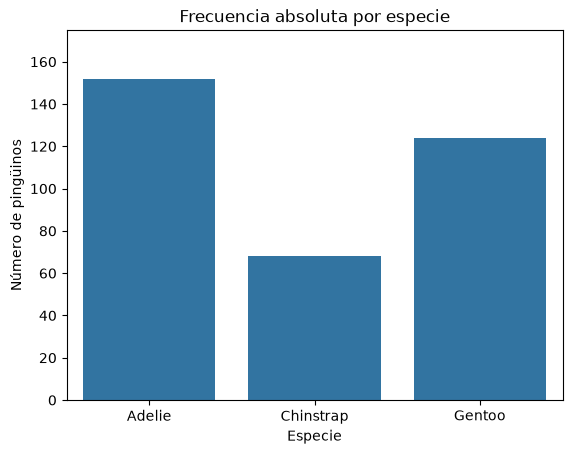

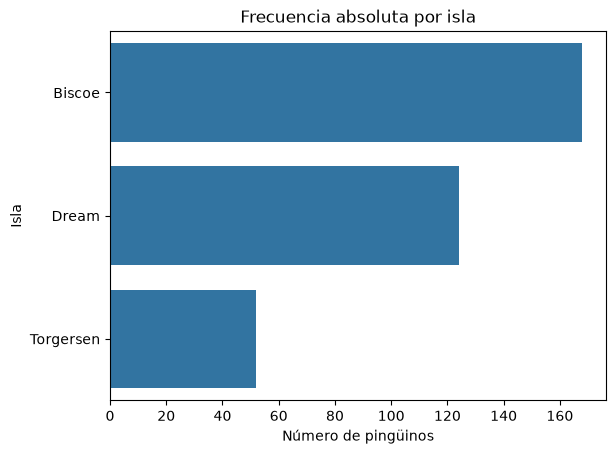

In [4]:
import seaborn as sns

import matplotlib.pyplot as plt

# Diagrama de barras verticales para species
sns.countplot(data=df, x="species")
plt.title("Frecuencia absoluta por especie")
plt.xlabel("Especie")
plt.ylabel("Número de pingüinos")
plt.ylim(0, df["species"].value_counts().max() * 1.15)
plt.show()

# Diagrama de barras horizontales para island
sns.countplot(data=df, y="island", order=df["island"].value_counts().index)
plt.title("Frecuencia absoluta por isla")
plt.xlabel("Número de pingüinos")
plt.ylabel("Isla")
plt.show()

► Ejercicio 2.3: Gráficos de Sectores (plt.pie) y Criterio de Selección Visual


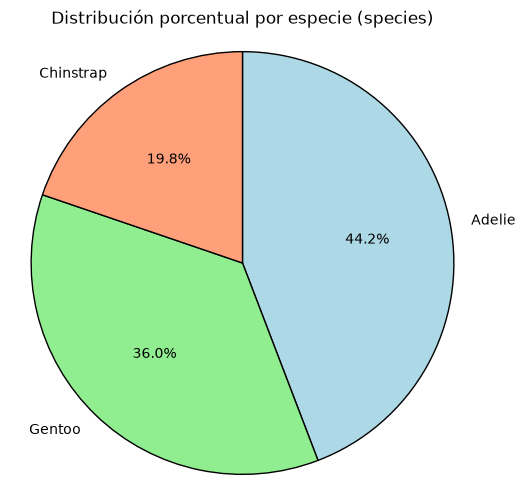

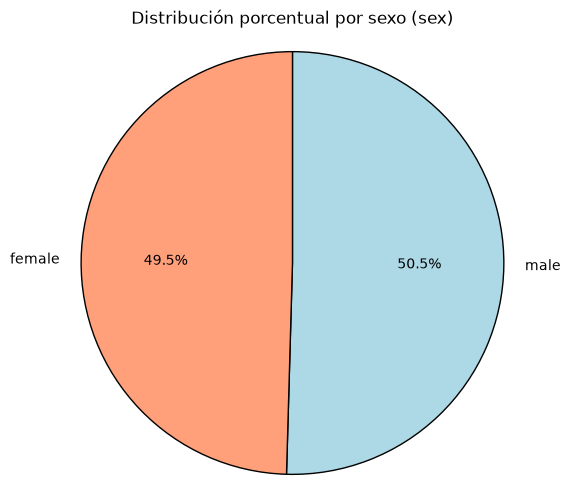

In [5]:
# Gráfico de sectores para species
frec_abs = df["species"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    frec_abs.values,
    labels=frec_abs.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=["lightblue", "lightgreen", "lightsalmon"],
    wedgeprops={"edgecolor": "black"}
)
plt.title("Distribución porcentual por especie (species)")
plt.axis("equal")
plt.show()

# Gráfico de sectores para sex, usando los registros completos
frec_sex = df_clean["sex"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    frec_sex.values,
    labels=frec_sex.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=["lightblue", "lightsalmon"],
    wedgeprops={"edgecolor": "black"}
)
plt.title("Distribución porcentual por sexo (sex)")
plt.axis("equal")
plt.show()

# 03 EDA UNIVARIANTE DE VARIABLES CONTINUAS: MÉTRICAS NUMÉRICAS Y FORMA
► Ejercicio 3.1: Tabla de Frecuencias Agrupadas por Intervalos de Clase (pd.cut y Marca de Clase)


In [6]:
serie_bm = df["body_mass_g"].dropna()

def tabla_frecuencias_agrupadas(serie, bins):
    intervalos = pd.cut(serie, bins=bins)
    freq = intervalos.value_counts().sort_index()
    f_rel = freq / len(serie)
    f_rel_acum = f_rel.cumsum()

    return pd.DataFrame({
        "Freq": freq,
        "F.Acum": freq.cumsum(),
        "F.R": f_rel.round(4),
        "F.R.Acum": f_rel_acum.round(4),
        "FR.Porc (%)": (f_rel * 100).round(2),
        "FRA.Porc (%)": (f_rel_acum * 100).round(2),
        "MC": [(iv.left + iv.right) / 2 for iv in freq.index]
    })

# Tabla con 6 intervalos
tabla_6 = tabla_frecuencias_agrupadas(serie_bm, bins=6)
print("Frecuencias agrupadas con 6 intervalos:")
display(tabla_6)

# Comparación con 10 intervalos, según Sturges
k_sturges = 1 + np.log2(len(serie_bm))
print(f"n = {len(serie_bm)}; k de Sturges = {k_sturges:.2f}; redondeado hacia arriba = {int(np.ceil(k_sturges))}")

tabla_10 = tabla_frecuencias_agrupadas(serie_bm, bins=10)
print("Frecuencias agrupadas con 10 intervalos:")
display(tabla_10)

Frecuencias agrupadas con 6 intervalos:


,Freq,F.Acum,F.R,F.R.Acum,FR.Porc (%),FRA.Porc (%),MC
body_mass_g,,,,,,,
"(2696.4, 3300.0]",40,40,0.1170,0.1170,11.70,11.70,2998.2
"(3300.0, 3900.0]",114,154,0.3333,0.4503,33.33,45.03,3600.0
"(3900.0, 4500.0]",73,227,0.2135,0.6637,21.35,66.37,4200.0
"(4500.0, 5100.0]",60,287,0.1754,0.8392,17.54,83.92,4800.0
"(5100.0, 5700.0]",43,330,0.1257,0.9649,12.57,96.49,5400.0
"(5700.0, 6300.0]",12,342,0.0351,1.0000,3.51,100.00,6000.0


n = 342; k de Sturges = 9.42; redondeado hacia arriba = 10
Frecuencias agrupadas con 10 intervalos:


,Freq,F.Acum,F.R,F.R.Acum,FR.Porc (%),FRA.Porc (%),MC
body_mass_g,,,,,,,
"(2696.4, 3060.0]",15,15,0.0439,0.0439,4.39,4.39,2878.2
"(3060.0, 3420.0]",43,58,0.1257,0.1696,12.57,16.96,3240.0
"(3420.0, 3780.0]",71,129,0.2076,0.3772,20.76,37.72,3600.0
"(3780.0, 4140.0]",53,182,0.1550,0.5322,15.50,53.22,3960.0
"(4140.0, 4500.0]",45,227,0.1316,0.6637,13.16,66.37,4320.0
"(4500.0, 4860.0]",38,265,0.1111,0.7749,11.11,77.49,4680.0
"(4860.0, 5220.0]",28,293,0.0819,0.8567,8.19,85.67,5040.0
"(5220.0, 5580.0]",27,320,0.0789,0.9357,7.89,93.57,5400.0
"(5580.0, 5940.0]",16,336,0.0468,0.9825,4.68,98.25,5760.0


► Ejercicio 3.2: Tendencia Central, Posición y Dispersión Global vs. Robusta


In [7]:
variables_biometricas = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

resumen = {}
cuartiles_por_variable = {}
percentiles_99 = {}
percentiles_extremos = {}

for variable in variables_biometricas:
    s = df[variable].dropna()

    cuartiles = s.quantile([0.25, 0.50, 0.75])
    iqr = cuartiles.loc[0.75] - cuartiles.loc[0.25]

    resumen[variable] = {
        "n": len(s),
        "Media": s.mean(),
        "Mediana": s.median(),
        "Moda": s.mode()[0],
        "Mínimo": s.min(),
        "Máximo": s.max(),
        "Rango total": s.max() - s.min(),
        "Varianza": s.var(),
        "Desviación estándar": s.std(),
        "Coeficiente de variación (%)": s.std() / s.mean() * 100,
        "IQR": iqr
    }

    cuartiles_por_variable[variable] = cuartiles
    percentiles_99[variable] = s.quantile([i / 100 for i in range(1, 100)])
    percentiles_extremos[variable] = s.quantile([0.05, 0.95])

tabla_resumen = pd.DataFrame(resumen).T
print("Tendencia central y dispersión:")
display(tabla_resumen.round(2))

print("Cuartiles:")
display(pd.DataFrame(cuartiles_por_variable).T.round(2))

print("Percentiles 5 y 95:")
display(pd.DataFrame(percentiles_extremos).T.round(2))

print("Percentiles 1–99:")
display(pd.DataFrame(percentiles_99).round(2))

Tendencia central y dispersión:


,n,Media,Mediana,Moda,Mínimo,Máximo,Rango total,Varianza,Desviación estándar,Coeficiente de variación (%),IQR
bill_length_mm,342.0,43.92,44.45,41.1,32.1,59.6,27.5,29.81,5.46,12.43,9.27
bill_depth_mm,342.0,17.15,17.30,17.0,13.1,21.5,8.4,3.90,1.97,11.51,3.10
flipper_length_mm,342.0,200.92,197.00,190.0,172.0,231.0,59.0,197.73,14.06,7.00,23.00
body_mass_g,342.0,4201.75,4050.00,3800.0,2700.0,6300.0,3600.0,643131.08,801.95,19.09,1200.00


Cuartiles:


,0.25,0.50,0.75
bill_length_mm,39.22,44.45,48.5
bill_depth_mm,15.60,17.30,18.7
flipper_length_mm,190.00,197.00,213.0
body_mass_g,3550.00,4050.00,4750.0


Percentiles 5 y 95:


,0.05,0.95
bill_length_mm,35.7,52.0
bill_depth_mm,13.9,20.0
flipper_length_mm,181.0,225.0
body_mass_g,3150.0,5650.0


Percentiles 1–99:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0.01,34.04,13.44,178.00,2900.0
0.02,34.58,13.68,178.82,2920.5
0.03,35.02,13.70,180.00,3011.5
0.04,35.43,13.80,181.00,3050.0
0.05,35.70,13.90,181.00,3150.0
...,...,...,...,...
0.95,52.00,20.00,225.00,5650.0
0.96,52.14,20.30,226.72,5700.0
0.97,52.65,20.58,228.00,5788.5
0.98,53.63,20.72,230.00,5850.0


► Ejercicio 3.3: Análisis de Forma: Asimetría de Fisher y Curtosis (scipy.stats.skew y kurtosis)


In [8]:
from scipy.stats import skew, kurtosis

cols_num = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

resultados = []

for col in cols_num:
    s = df[col].dropna()
    asimetria = skew(s)
    curtosis_bruta = kurtosis(s, fisher=False)
    exceso_curtosis = kurtosis(s, fisher=True)

    if abs(asimetria) < 0.5:
        clase_asimetria = "aproximadamente simétrica"
    elif asimetria > 0:
        clase_asimetria = "asimetría positiva"
    else:
        clase_asimetria = "asimetría negativa"

    if exceso_curtosis > 0:
        clase_apuntamiento = "leptocúrtica"
    elif exceso_curtosis < 0:
        clase_apuntamiento = "platicúrtica"
    else:
        clase_apuntamiento = "mesocúrtica"

    resultados.append({
        "Variable": col,
        "Skew": asimetria,
        "Curtosis bruta": curtosis_bruta,
        "Exceso de curtosis": exceso_curtosis,
        "Asimetría": clase_asimetria,
        "Apuntamiento": clase_apuntamiento
    })

tabla_forma = pd.DataFrame(resultados).set_index("Variable")
display(tabla_forma.round(4))

,Skew,Curtosis bruta,Exceso de curtosis,Asimetría,Apuntamiento
Variable,,,,,
bill_length_mm,0.0529,2.1192,-0.8808,aproximadamente simétrica,platicúrtica
bill_depth_mm,-0.1428,2.0888,-0.9112,aproximadamente simétrica,platicúrtica
flipper_length_mm,0.3442,2.0126,-0.9874,aproximadamente simétrica,platicúrtica
body_mass_g,0.4683,2.2738,-0.7262,aproximadamente simétrica,platicúrtica


# 04 VISUALIZACIÓN UNIVARIANTE CONTINUA: HISTOGRAMAS, KDE Y BOXPLOTS
► Ejercicio 4.1: Histogramas y Curva de Densidad Superpuesta (sns.histplot con kde=True y axvline)


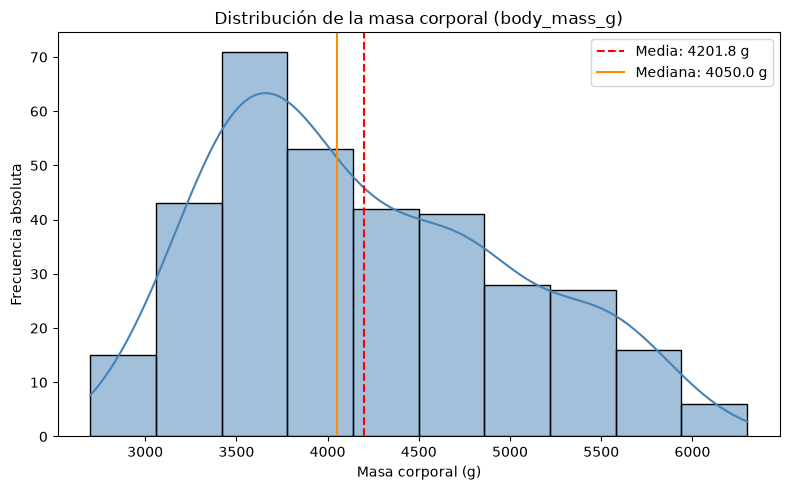

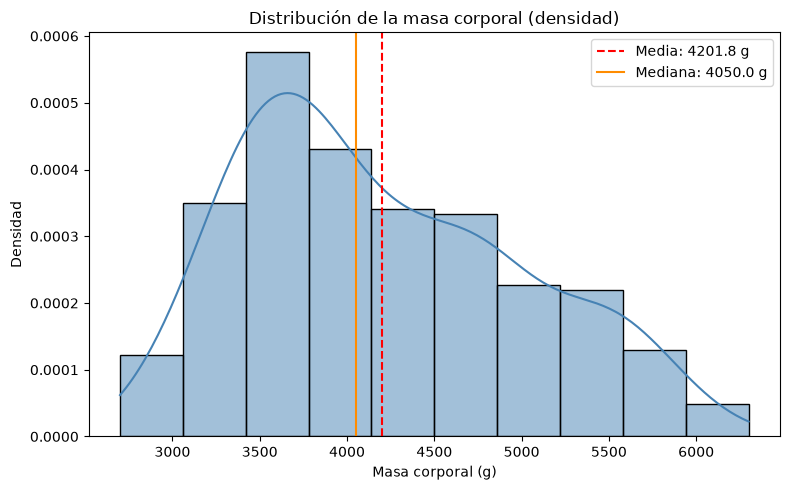

In [9]:
# Histograma con curva de densidad y líneas de referencia (Media vs. Mediana)
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='body_mass_g', bins=10, kde=True, color='steelblue', edgecolor='black')
plt.axvline(df['body_mass_g'].mean(), color='red', linestyle='--', linewidth=1.5,
            label=f"Media: {df['body_mass_g'].mean():.1f} g")
plt.axvline(df['body_mass_g'].median(), color='darkorange', linestyle='-', linewidth=1.5,
            label=f"Mediana: {df['body_mass_g'].median():.1f} g")
plt.title('Distribución de la masa corporal (body_mass_g)')
plt.xlabel('Masa corporal (g)')
plt.ylabel('Frecuencia absoluta')
plt.legend()
plt.tight_layout()
plt.show()

# Histograma normalizado con curva de densidad y líneas de referencia
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='body_mass_g', bins=10, kde=True, stat='density',
             color='steelblue', edgecolor='black')
plt.axvline(df['body_mass_g'].mean(), color='red', linestyle='--', linewidth=1.5,
            label=f"Media: {df['body_mass_g'].mean():.1f} g")
plt.axvline(df['body_mass_g'].median(), color='darkorange', linestyle='-', linewidth=1.5,
            label=f"Mediana: {df['body_mass_g'].median():.1f} g")
plt.title('Distribución de la masa corporal (densidad)')
plt.xlabel('Masa corporal (g)')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()
plt.show()

► Ejercicio 4.2: Función de Densidad de Probabilidad (sns.kdeplot) y Diagnóstico de Modalidad


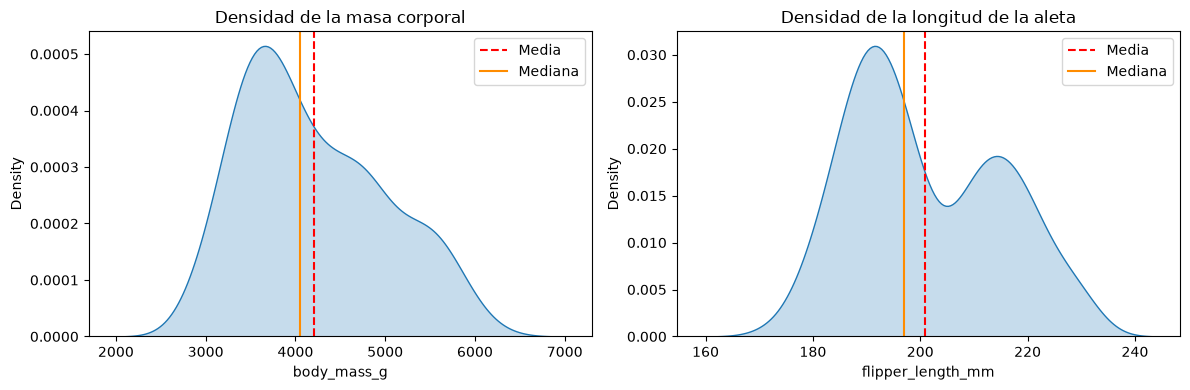

In [10]:
# Comparativa de funciones de densidad (KDE) con media y mediana
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(data=df, x="body_mass_g", fill=True, ax=axes[0])
axes[0].axvline(df["body_mass_g"].mean(), color="red", linestyle="--",
                linewidth=1.5, label="Media")
axes[0].axvline(df["body_mass_g"].median(), color="darkorange",
                linestyle="-", linewidth=1.5, label="Mediana")
axes[0].set_title("Densidad de la masa corporal")
axes[0].legend()

sns.kdeplot(data=df, x="flipper_length_mm", fill=True, ax=axes[1])
axes[1].axvline(df["flipper_length_mm"].mean(), color="red", linestyle="--",
                linewidth=1.5, label="Media")
axes[1].axvline(df["flipper_length_mm"].median(), color="darkorange",
                linestyle="-", linewidth=1.5, label="Mediana")
axes[1].set_title("Densidad de la longitud de la aleta")
axes[1].legend()

plt.tight_layout()
plt.show()

► Ejercicio 4.3: Diagramas de Cajas (sns.boxplot) con Media Marcada y Detección de Outliers (1.5·IQR)


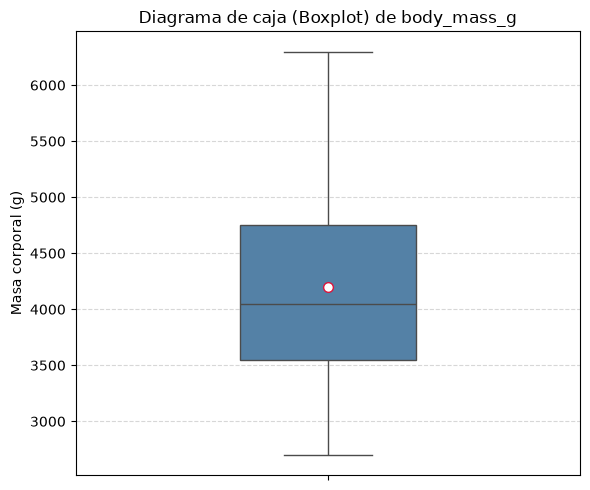

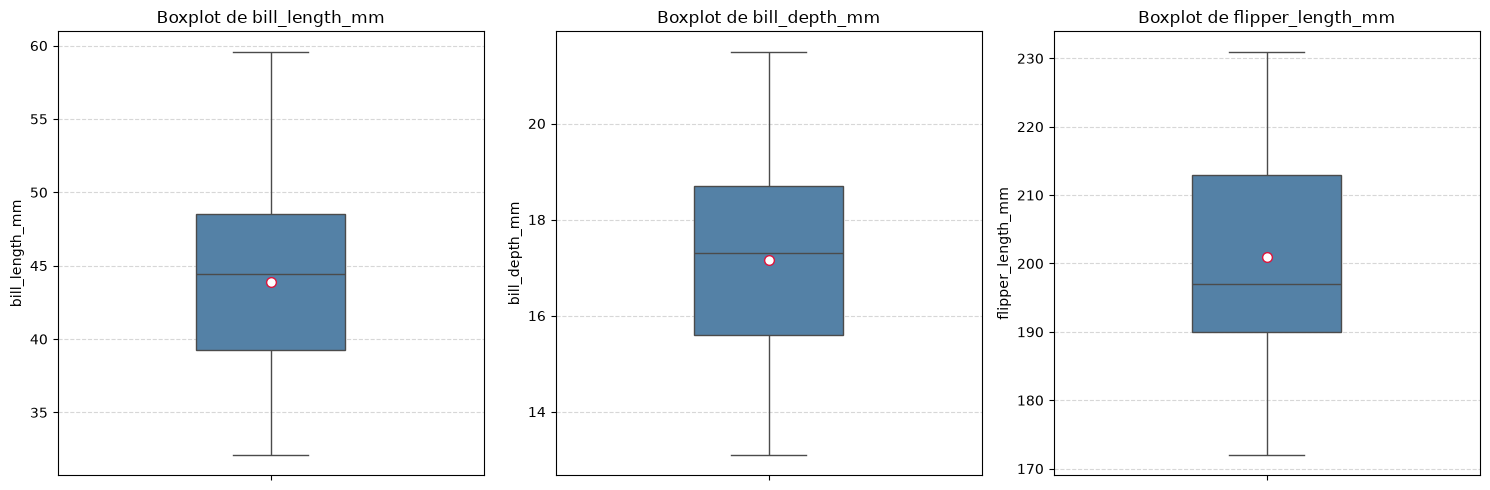

Q1: 3550.00 g
Q3: 4750.00 g
IQR: 1200.00 g
Límite inferior: 1750.00 g
Límite superior: 6550.00 g
Número de outliers: 0
Valores atípicos:


Series([], Name: body_mass_g, dtype: float64)

In [11]:
# Boxplot de body_mass_g con la media marcada
plt.figure(figsize=(6, 5))
sns.boxplot(
    data=df,
    y="body_mass_g",
    width=0.35,
    color="steelblue",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "crimson",
        "markersize": 7
    }
)
plt.title("Diagrama de caja (Boxplot) de body_mass_g")
plt.ylabel("Masa corporal (g)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Boxplots de las demás variables continuas
variables_restantes = [
    variable for variable in variables_biometricas
    if variable != "body_mass_g"
]

fig_box, ejes_box = plt.subplots(1, 3, figsize=(15, 5))

for ax, variable in zip(ejes_box, variables_restantes):
    sns.boxplot(
        data=df,
        y=variable,
        width=0.35,
        color="steelblue",
        showmeans=True,
        meanprops={
            "marker": "o",
            "markerfacecolor": "white",
            "markeredgecolor": "crimson",
            "markersize": 7
        },
        ax=ax
    )
    ax.set_title(f"Boxplot de {variable}")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Detección de outliers en body_mass_g mediante la regla de Tukey
masa = df["body_mass_g"].dropna()
q1 = masa.quantile(0.25)
q3 = masa.quantile(0.75)
iqr_masa = q3 - q1
lim_inf = q1 - 1.5 * iqr_masa
lim_sup = q3 + 1.5 * iqr_masa

outliers = masa[(masa < lim_inf) | (masa > lim_sup)]

print(f"Q1: {q1:.2f} g")
print(f"Q3: {q3:.2f} g")
print(f"IQR: {iqr_masa:.2f} g")
print(f"Límite inferior: {lim_inf:.2f} g")
print(f"Límite superior: {lim_sup:.2f} g")
print(f"Número de outliers: {len(outliers)}")
print("Valores atípicos:")
display(outliers)